# Notebook 17 — Fixed fusion × classifier benchmark

Chạy 7 fusion × 4 classifier trên `B_with_geometry`, với seed 5, 6, 7, 37, 42. Cả 7 fusion dùng NTv1 DNA + ESM1b protein và geometry k=64 tương ứng ESM1b. Cross-Attention nạp checkpoint Step 2 đã train cho từng seed; sáu fusion còn lại được train trong batch này. Batch size train là 128 để tăng throughput. Optuna đang tắt. Notebook lưu checkpoint, resume, test từng dataset, profiling và mean/std theo seed.

## 1. Cấu hình batch, mô hình và tham số ML cũ
Chỉnh `BATCH_RUN_DIR_OVERRIDE` nếu muốn resume một batch cụ thể. Có thể đổi `BATCH_SIZE` khi resume; checkpoint neural được lưu theo epoch nên epoch chưa hoàn tất sẽ chạy lại nếu bị ngắt giữa chừng. Kiến trúc, dữ liệu và hyperparameter khác vẫn phải giữ nguyên. Để tạo batch mới, đặt `RESUME_BENCHMARK_BATCH=False`. Optuna hiện tắt. Cell kiểm tra manifest và validation record của 5 checkpoint Cross-Attention trước khi tiếp tục.

In [1]:
from datetime import datetime
from pathlib import Path
import importlib, json, os, sys
import pandas as pd
import torch
from IPython.display import display

_cwd = Path.cwd().resolve()
REPO_ROOT = next((p for p in (_cwd, *_cwd.parents) if (p / 'core').is_dir() and (p / 'controllers').is_dir()), _cwd)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from core.module05v2_fusion_classifier.pipeline import FusionBatchPipeline
from core.module06_architecture_experiments.fm_ablation_preparation import (
    build_model_configs, build_split_configs, inspect_token_cache, extract_missing_token_caches,
)
from core.module06_architecture_experiments.fusion_classifier_benchmark import (
    load_legacy_best_classifier_params, run_fixed_fusion_classifier_benchmark,
)

BASE_DIR = Path(r'F:\variant_data')
POOLED_CACHE_ROOT = BASE_DIR / 'fm_embeddings' / 'sequence_ablation'
TOKEN_CACHE_ROOT = BASE_DIR / 'fm_embeddings' / 'token_level_cache' / 'module06'
GEOMETRY_K = 64
GEOMETRY_ROOT_NAME = 'geometry_v2_k64_step2_matched'
GEOMETRY_ROOT = BASE_DIR / GEOMETRY_ROOT_NAME / '{context}'
FM_PROFILE_JSON = BASE_DIR / 'profiling' / 'fm_profiling_sequence_ablation.json'
GEOM_FEATURE_NAMES = [f'{mod}_{feature}' for mod in ('dna', 'prot') for feature in ('LVD_L2', 'LVD_Cosine', 'LID', 'LVD_Relative')]
SEEDS = [5, 6, 7, 37, 42]
BATCH_SIZE = 64  # Larger training/inference batches to improve GPU throughput.
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

FIXED_MODEL_CONFIG = {
    'attention_dropout': 0.18776012701077605, 'dropout': 0.1955626033738947,
    'early_stop_patience': 6, 'feature_dropout': 0.2507543060224074,
    'ffn_multiplier': 4, 'k_radius': 16, 'learning_rate': 0.00012206472463506827,
    'lr_factor': 0.5, 'lr_patience': 3, 'max_epochs': 30, 'model_dim': 512,
    'num_heads': 8, 'num_layers': 3, 'pooling': 'mean',
    'weight_decay': 3.380881049679085e-06,
}
OPTUNA_CONFIG = {'enabled': False, 'direction': 'maximize', 'objective': 'mean_validation_mcc', 'n_trials': 0}

RESUME_BENCHMARK_BATCH = True
BATCH_RUN_DIR_OVERRIDE = None  # Optional explicit folder; e.g. REPO_ROOT / 'experiments' / 'fusion_classifier_benchmark_...'
BATCH_POINTER = REPO_ROOT / 'experiments' / '_fusion_classifier_benchmark_latest_batch.json'
if BATCH_RUN_DIR_OVERRIDE is not None:
    BATCH_RUN_DIR = Path(BATCH_RUN_DIR_OVERRIDE).resolve()
elif RESUME_BENCHMARK_BATCH and BATCH_POINTER.is_file():
    BATCH_RUN_DIR = Path(json.loads(BATCH_POINTER.read_text(encoding='utf-8-sig'))['batch_run_dir']).resolve()
else:
    BATCH_RUN_DIR = REPO_ROOT / 'experiments' / f'fusion_classifier_benchmark_{datetime.now():%Y%m%d_%H%M%S}'
    BATCH_POINTER.parent.mkdir(parents=True, exist_ok=True)
    BATCH_POINTER.write_text(json.dumps({'batch_run_dir': str(BATCH_RUN_DIR.resolve())}, indent=2), encoding='utf-8')
BATCH_RUN_DIR.mkdir(parents=True, exist_ok=True)

DNA_MODEL_NAME = 'nt_v1_500m_dna_1001'
PROTEIN_MODEL_NAME = 'esm1b_650m_prot_501'
_models = build_model_configs(dna_length=1001, protein_length=501)
DNA_MODEL = next(m for m in _models if m['name'] == DNA_MODEL_NAME)
PROTEIN_MODEL = next(m for m in _models if m['name'] == PROTEIN_MODEL_NAME)
SPLITS = build_split_configs(BASE_DIR)
TARGET_CONFIGS = [{
    'name': 'B_with_geometry', 'ablation': 'bio_core_dna_prot_spliceai_geom',
    'active_modalities': ['dna', 'prot', 'bio_core', 'spliceai', 'geom'],
    'geom_feature_names': GEOM_FEATURE_NAMES,
    'geometry_dna_name': DNA_MODEL_NAME, 'geometry_protein_name': PROTEIN_MODEL_NAME,
}]
DATASETS = [
    {'name': 'Train3Val_Test', 'train': 'train3', 'val': 'val', 'test': 'test'},
    {'name': 'Train3Val_ClinVarHQ', 'train': 'train3', 'val': 'val', 'test': 'clinvarhq'},
    {'name': 'Train3Val_ProteinGym', 'train': 'train3', 'val': 'val', 'test': 'proteingym'},
    {'name': 'Train3Val_UniProt', 'train': 'train3', 'val': 'val', 'test': 'uniprot'},
]
PRETRAINED_CA_RUNS_ROOT = REPO_ROOT / 'experiments' / 'fm_ablation_20261117_003149' / 'module06_architecture_experiments' / 'step2_sequence_length_ablation' / 'runs'
CA_SOURCE_ARCHITECTURE = 'cross_attention_3modal_ref_alt_concat_window33_sequence_length_ablation'
CA_SOURCE_VARIANT = 'ref_alt_concat_window_33_sequence_length_ablation'

def _load_pretrained_cross_attention(seed):
    run_name = f'step2_nt_v1_dna1001_esm1b_prot501_seed{seed}'
    run_dir = PRETRAINED_CA_RUNS_ROOT / run_name
    checkpoint = run_dir / 'checkpoints' / 'B_with_geometry' / 'best_model.pth'
    manifest_path = run_dir / '_resume_manifest.json'
    if not checkpoint.is_file() or not manifest_path.is_file():
        raise FileNotFoundError(f'Missing Cross-Attention checkpoint or manifest for seed {seed}: {run_dir}')
    manifest = json.loads(manifest_path.read_text(encoding='utf-8'))
    saved = manifest.get('config', {})
    mismatches = []
    if saved.get('architecture') != CA_SOURCE_ARCHITECTURE:
        mismatches.append('architecture')
    if saved.get('variant') != CA_SOURCE_VARIANT:
        mismatches.append('variant')
    if saved.get('dna_model', {}).get('name') != DNA_MODEL_NAME:
        mismatches.append('DNA model')
    if saved.get('protein_model', {}).get('name') != PROTEIN_MODEL_NAME:
        mismatches.append('protein model')
    input_signature = saved.get('input_data_signature', {})
    if input_signature.get('geometry_root') != GEOMETRY_ROOT_NAME:
        mismatches.append('geometry root')
    if input_signature.get('token_window') != 'variant-centered ref/alt, k_radius=16, length=33':
        mismatches.append('token window')
    target = saved.get('target_configs', [{}])[0]
    if target.get('name') != 'B_with_geometry' or target.get('geom_feature_names') != GEOM_FEATURE_NAMES:
        mismatches.append('target/geometry features')
    config_keys = [key for key in saved if key.startswith(run_name + '_config')]
    if len(config_keys) != 1:
        mismatches.append('seed-specific model config')
        source_config = {}
    else:
        source_config = saved[config_keys[0]]
        expected_config = {**FIXED_MODEL_CONFIG, 'seed': int(seed)}
        if any(source_config.get(key) != value for key, value in expected_config.items()):
            mismatches.append('fixed model hyperparameters')
    validation_files = list(run_dir.glob('*_validation_metrics.csv'))
    if not validation_files:
        mismatches.append('validation metrics')
        validation_row = {}
    else:
        validation_frame = pd.read_csv(validation_files[0])
        selected = validation_frame[
            validation_frame['Target_Config'].astype(str).eq('B_with_geometry')
            & pd.to_numeric(validation_frame['Seed'], errors='coerce').eq(int(seed))
        ]
        if selected.empty:
            mismatches.append('seed/B validation row')
            validation_row = {}
        else:
            validation_row = selected.iloc[0].to_dict()
    if mismatches:
        raise ValueError(f'Cross-Attention source for seed {seed} does not match this benchmark: {mismatches}')
    return {
        'checkpoint': str(checkpoint.resolve()),
        'manifest': str(manifest_path.resolve()),
        'validation_csv': str(validation_files[0].resolve()),
        'best_epoch': int(validation_row.get('Best_Epoch', 1)),
        'source_val_mcc': float(validation_row.get('Val_MCC', float('nan'))),
    }

PRETRAINED_CA_CHECKPOINTS = {seed: _load_pretrained_cross_attention(seed) for seed in SEEDS}
PRETRAINED_CA_AUDIT = pd.DataFrame([
    {'Seed': seed, 'Checkpoint': item['checkpoint'], 'Best_Epoch': item['best_epoch'],
     'Source_Val_MCC': item['source_val_mcc'], 'Status': 'ready'}
    for seed, item in PRETRAINED_CA_CHECKPOINTS.items()
])
display(PRETRAINED_CA_AUDIT)

PIPELINE_CONFIG = {
    'batch_size': BATCH_SIZE, 'epochs': FIXED_MODEL_CONFIG['max_epochs'],
    'lr': FIXED_MODEL_CONFIG['learning_rate'], 'weight_decay': FIXED_MODEL_CONFIG['weight_decay'],
    'lr_factor': FIXED_MODEL_CONFIG['lr_factor'], 'lr_patience': FIXED_MODEL_CONFIG['lr_patience'],
    'early_stop_patience': FIXED_MODEL_CONFIG['early_stop_patience'], 'num_workers': 0,
    'seed': SEEDS[0], 'xgb_n_jobs': 1,
}
pipeline = FusionBatchPipeline(
    base_dir=str(BASE_DIR), config=PIPELINE_CONFIG, datasets=DATASETS,
    models_space=[DNA_MODEL, PROTEIN_MODEL], pooling_strategies=['center'],
    experiments=[{'name': 'FusionClassifierBenchmark', 'type': 'pytorch', 'fusion': 'concat'}],
    explainability={'enable_shap': False, 'enable_lime': False},
    fm_profile_json=str(FM_PROFILE_JSON), geom_profile_json=None,
    geometry_dir=str(GEOMETRY_ROOT), geom_feature_names=GEOM_FEATURE_NAMES,
    batch_run_dir=str(BATCH_RUN_DIR), embedding_dir=str(POOLED_CACHE_ROOT),
)

LEGACY_ML_BATCH_DIR = REPO_ROOT / 'experiments' / 'optimization_fixed_config_20261018_064727'
LEGACY_BEST_PARAMS = load_legacy_best_classifier_params(LEGACY_ML_BATCH_DIR, target_config='B_with_geometry')
LEGACY_BEST_PARAMS_TABLE = pd.DataFrame([
    {'Classifier': name, 'Source_Trial': value['source_trial'],
     'Source_Val_MCC': value['source_val_mcc'], 'Source_CSV': value['source_csv'],
     'Parameters': json.dumps(value['params'], sort_keys=True)}
    for name, value in LEGACY_BEST_PARAMS.items()
])
print('Batch pointer:', BATCH_POINTER)
print('Batch:', BATCH_RUN_DIR)
print('Device:', DEVICE, '| target:', TARGET_CONFIGS[0]['name'], '| seeds:', SEEDS)
print('Fixed shared model config:', FIXED_MODEL_CONFIG)
print('Optuna enabled:', OPTUNA_CONFIG['enabled'])
display(LEGACY_BEST_PARAMS_TABLE)


c:\Users\Dung\anaconda3\envs\missense_variant_patho_predict_clean\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,Seed,Checkpoint,Best_Epoch,Source_Val_MCC,Status
0,5,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8209,ready
1,6,D:\Missense_variant_pathogenicity_prediction\e...,4,0.8238,ready
2,7,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8235,ready
3,37,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8243,ready
4,42,D:\Missense_variant_pathogenicity_prediction\e...,2,0.8210,ready


Batch pointer: D:\Missense_variant_pathogenicity_prediction\experiments\_fusion_classifier_benchmark_latest_batch.json
Batch: D:\Missense_variant_pathogenicity_prediction\experiments\fusion_classifier_benchmark_20261120_192605
Device: cuda | target: B_with_geometry | seeds: [5, 6, 7, 37, 42]
Fixed shared model config: {'attention_dropout': 0.18776012701077605, 'dropout': 0.1955626033738947, 'early_stop_patience': 6, 'feature_dropout': 0.2507543060224074, 'ffn_multiplier': 4, 'k_radius': 16, 'learning_rate': 0.00012206472463506827, 'lr_factor': 0.5, 'lr_patience': 3, 'max_epochs': 30, 'model_dim': 512, 'num_heads': 8, 'num_layers': 3, 'pooling': 'mean', 'weight_decay': 3.380881049679085e-06}
Optuna enabled: False


,Classifier,Source_Trial,Source_Val_MCC,Source_CSV,Parameters
0,XGBoost,optuna_0017,0.8343,D:\Missense_variant_pathogenicity_prediction\e...,"{""colsample_bytree"": 0.4252579869859605, ""earl..."
1,LightGBM,optuna_0016,0.8342,D:\Missense_variant_pathogenicity_prediction\e...,"{""colsample_bytree"": 0.4269560174095951, ""lear..."
2,CatBoost,optuna_0020,0.8309,D:\Missense_variant_pathogenicity_prediction\e...,"{""allow_writing_files"": false, ""depth"": 9, ""ev..."


## 2. Cache preflight và resume an toàn
Kiểm tra pooled cache, token cache và geometry k=64 cho đúng FM pair/split. Token extraction chỉ bổ sung phần thiếu, chạy offline như Notebook 14. Nếu dữ liệu không đầy đủ, cell dừng trước khi train.

In [2]:
from core.module05v2_fusion_classifier import pipeline as pipeline_module

required_split_names = [split['name'] for split in SPLITS]
pooled_rows = []
for split_name in required_split_names:
    for model in (DNA_MODEL, PROTEIN_MODEL):
        path = POOLED_CACHE_ROOT / split_name / f"{model['name']}_center.pt"
        pooled_rows.append({'Split': split_name, 'Model': model['name'],
                           'Status': 'complete' if path.is_file() else 'missing', 'Path': str(path)})
POOLED_CACHE_AUDIT = pd.DataFrame(pooled_rows)
display(POOLED_CACHE_AUDIT)
if (POOLED_CACHE_AUDIT['Status'] != 'complete').any():
    raise FileNotFoundError('Required center-pooled cache is missing; inspect POOLED_CACHE_AUDIT.')

GEOMETRY_AUDIT = []
for split_name in required_split_names:
    for model_name in (DNA_MODEL_NAME, PROTEIN_MODEL_NAME):
        resolved = pipeline_module._resolve_geom_path(
            str(GEOMETRY_ROOT).format(context='train3'), split_name, model_name, 'center'
        )
        GEOMETRY_AUDIT.append({'Split': split_name, 'Model': model_name, 'Path': resolved})
display(pd.DataFrame(GEOMETRY_AUDIT))

os.environ['HF_HUB_OFFLINE'] = '1'
TOKEN_CACHE_PREPARATION = extract_missing_token_caches(
    model_configs=[DNA_MODEL, PROTEIN_MODEL], split_configs=SPLITS,
    cache_root=TOKEN_CACHE_ROOT, batch_run_dir=BATCH_RUN_DIR,
    device=str(DEVICE),
)
TOKEN_CACHE_INDEX = TOKEN_CACHE_PREPARATION['index']
TOKEN_CACHE_AUDIT = pd.DataFrame(inspect_token_cache(TOKEN_CACHE_ROOT, [DNA_MODEL, PROTEIN_MODEL], SPLITS))
display(TOKEN_CACHE_AUDIT[['Model', 'Split', 'Status', 'Shards', 'Path']])
if TOKEN_CACHE_PREPARATION.get('status') != 'complete' or (TOKEN_CACHE_AUDIT['Status'] != 'complete').any():
    raise RuntimeError('Token cache incomplete; training has not started. Resume extraction and rerun this cell.')

BENCHMARK_CONTEXT = {
    'pipeline': pipeline, 'TARGET_CONFIGS': TARGET_CONFIGS, 'datasets': DATASETS,
    'DNA_MODEL': DNA_MODEL, 'PROTEIN_MODEL': PROTEIN_MODEL, 'DEVICE': DEVICE,
    'token_embedding_cache_index': TOKEN_CACHE_INDEX, 'token_batch_size': BATCH_SIZE,
    'pretrained_encoder_checkpoints': PRETRAINED_CA_CHECKPOINTS,
    'allow_batch_size_resume': True,
    'input_data_signature': {
        'geometry_k': GEOMETRY_K, 'geometry_root': GEOMETRY_ROOT_NAME, 'geometry_features': GEOM_FEATURE_NAMES,
        'token_models': [DNA_MODEL_NAME, PROTEIN_MODEL_NAME],
        'target_config': 'B_with_geometry', 'embedding_representation': 'ref_alt_concat',
    },
}
print('Preflight complete. Resume enabled at:', BATCH_RUN_DIR)


,Split,Model,Status,Path
0,train3,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
1,train3,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
2,val,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
3,val,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
4,test,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
5,test,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
6,clinvarhq,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
7,clinvarhq,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
8,proteingym,nt_v1_500m_dna_1001,complete,F:\variant_data\fm_embeddings\sequence_ablatio...
9,proteingym,esm1b_650m_prot_501,complete,F:\variant_data\fm_embeddings\sequence_ablatio...


,Split,Model,Path
0,train3,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
1,train3,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
2,val,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
3,val,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
4,test,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
5,test,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
6,clinvarhq,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
7,clinvarhq,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...
8,proteingym,nt_v1_500m_dna_1001,F:\variant_data\geometry_v2_k64_step2_matched\...
9,proteingym,esm1b_650m_prot_501,F:\variant_data\geometry_v2_k64_step2_matched\...


,Model,Split,Status,Shards,Path
0,nt_v1_500m_dna_1001,train3,complete,11604,F:\variant_data\fm_embeddings\token_level_cach...
1,nt_v1_500m_dna_1001,val,complete,6851,F:\variant_data\fm_embeddings\token_level_cach...
2,nt_v1_500m_dna_1001,test,complete,3048,F:\variant_data\fm_embeddings\token_level_cach...
3,nt_v1_500m_dna_1001,clinvarhq,complete,352,F:\variant_data\fm_embeddings\token_level_cach...
4,nt_v1_500m_dna_1001,proteingym,complete,736,F:\variant_data\fm_embeddings\token_level_cach...
5,nt_v1_500m_dna_1001,uniprot,complete,667,F:\variant_data\fm_embeddings\token_level_cach...
6,esm1b_650m_prot_501,train3,complete,1451,F:\variant_data\fm_embeddings\token_level_cach...
7,esm1b_650m_prot_501,val,complete,857,F:\variant_data\fm_embeddings\token_level_cach...
8,esm1b_650m_prot_501,test,complete,381,F:\variant_data\fm_embeddings\token_level_cach...
9,esm1b_650m_prot_501,clinvarhq,complete,44,F:\variant_data\fm_embeddings\token_level_cach...


Preflight complete. Resume enabled at: D:\Missense_variant_pathogenicity_prediction\experiments\fusion_classifier_benchmark_20261120_192605


## 3. Train, evaluate, profile and resume all combinations
Cross-Attention nạp checkpoint có sẵn theo từng seed và không train encoder/MLP lại; validation threshold được tính lại trên validation hiện tại. Sáu fusion còn lại train trong batch này và resume theo epoch. Feature cache/tree head đã hoàn tất được dùng lại; các lượt dang dở được tiếp tục. Chọn threshold bằng validation; test chỉ dùng để báo cáo.

In [3]:
import importlib
benchmark_module = importlib.reload(importlib.import_module(
    'core.module06_architecture_experiments.fusion_classifier_benchmark'
))
BENCHMARK_RESULTS = benchmark_module.run_fixed_fusion_classifier_benchmark(
    context=BENCHMARK_CONTEXT,
    shared_config={**FIXED_MODEL_CONFIG, 'batch_size': BATCH_SIZE},
    seeds=SEEDS,
    legacy_classifier_params=LEGACY_BEST_PARAMS,
    display_fn=display,
)
print('Saved benchmark outputs under:', BENCHMARK_RESULTS['output_root'])


[RESUME] All Concat_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[RESUME] Concat_ThreeModalities/MLP/seed_5: global test predictions already synchronized.
[RESUME] Concat_ThreeModalities/XGBoost/seed_5 is complete; skipping feature and dataset loading.
[RESUME] Concat_ThreeModalities/XGBoost/seed_5: global test predictions already synchronized.
[RESUME] Concat_ThreeModalities/CatBoost/seed_5 is complete; skipping feature and dataset loading.
[RESUME] Concat_ThreeModalities/CatBoost/seed_5: global test predictions already synchronized.
[RESUME] Concat_ThreeModalities/LightGBM/seed_5 is complete; skipping feature and dataset loading.
[RESUME] Concat_ThreeModalities/LightGBM/seed_5: global test predictions already synchronized.
[RESUME] All Concat_ThreeModalities targets and test outputs are complete; skipping data loading and training.
[RESUME] Concat_ThreeModalities/MLP/seed_6: global test predictions already synchronized.
[RESUME] Concat_Th

'[TEST] LowRank/CatBoost/seed_7 Train3Val_Test: MCC=0.8227'

'[TEST] LowRank/CatBoost/seed_7 Train3Val_ClinVarHQ: MCC=0.8476'

'[TEST] LowRank/CatBoost/seed_7 Train3Val_ProteinGym: MCC=0.6677'

'[TEST] LowRank/CatBoost/seed_7 Train3Val_UniProt: MCC=0.5094'

[SYNC] Merging saved CatBoost test predictions for LowRank/seed_7...


... (1,362 outputs left out)

,Target_Config,Fusion,Classifier,Dataset,Accuracy_mean,Accuracy_std,Accuracy_count,Precision_mean,Precision_std,Precision_count,...,E2E_Total_Params_count,E2E_Param_Mem_MB_mean,E2E_Param_Mem_MB_std,E2E_Param_Mem_MB_count,Max_Peak_VRAM_MB_mean,Max_Peak_VRAM_MB_std,Max_Peak_VRAM_MB_count,Classifier_Tree_Leaves_mean,Classifier_Tree_Leaves_std,Classifier_Tree_Leaves_count
0,B_with_geometry,Concat_ThreeModalities,CatBoost,Train3Val_ClinVarHQ,0.91946,0.005079,5,0.96432,0.003666,5,...,5,2183.77,0.0,5,2132.94,0.0,5,507494.4,219077.794139,5
1,B_with_geometry,Concat_ThreeModalities,CatBoost,Train3Val_ProteinGym,0.82908,0.005096,5,0.77664,0.006991,5,...,5,2183.77,0.0,5,2132.94,0.0,5,507494.4,219077.794139,5
2,B_with_geometry,Concat_ThreeModalities,CatBoost,Train3Val_Test,0.92654,0.001692,5,0.88246,0.007760,5,...,5,2183.77,0.0,5,2132.94,0.0,5,507494.4,219077.794139,5
3,B_with_geometry,Concat_ThreeModalities,CatBoost,Train3Val_UniProt,0.76126,0.002144,5,0.76156,0.007577,5,...,5,2183.77,0.0,5,2132.94,0.0,5,507494.4,219077.794139,5
4,B_with_geometry,Concat_ThreeModalities,LightGBM,Train3Val_ClinVarHQ,0.91834,0.009884,5,0.96364,0.004731,5,...,5,2183.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
107,B_with_geometry,Transformer_ThreeModalities,MLP,Train3Val_UniProt,0.75392,0.008924,5,0.74814,0.009110,5,...,5,2218.90,0.0,5,2132.94,0.0,5,NaN,NaN,0
108,B_with_geometry,Transformer_ThreeModalities,XGBoost,Train3Val_ClinVarHQ,0.92006,0.007678,5,0.97220,0.003450,5,...,5,2218.90,0.0,5,2132.94,0.0,5,8988.2,648.075767,5
109,B_with_geometry,Transformer_ThreeModalities,XGBoost,Train3Val_ProteinGym,0.81794,0.005531,5,0.76202,0.017421,5,...,5,2218.90,0.0,5,2132.94,0.0,5,8988.2,648.075767,5
110,B_with_geometry,Transformer_ThreeModalities,XGBoost,Train3Val_Test,0.92594,0.001354,5,0.87786,0.018481,5,...,5,2218.90,0.0,5,2132.94,0.0,5,8988.2,648.075767,5


,Target_Config,Fusion,Classifier,FM_GFLOPs/Sample_mean,FM_GFLOPs/Sample_std,FM_GFLOPs/Sample_count,FM_Latency_ms/Sample_mean,FM_Latency_ms/Sample_std,FM_Latency_ms/Sample_count,Geom_GFLOPs/Sample_mean,...,E2E_Total_Params_count,E2E_Param_Mem_MB_mean,E2E_Param_Mem_MB_std,E2E_Param_Mem_MB_count,Max_Peak_VRAM_MB_mean,Max_Peak_VRAM_MB_std,Max_Peak_VRAM_MB_count,Classifier_Tree_Leaves_mean,Classifier_Tree_Leaves_std,Classifier_Tree_Leaves_count
0,B_with_geometry,Concat_ThreeModalities,CatBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2183.77,0.0,5,2132.94,0.0,5,507494.4,219077.794139,5
1,B_with_geometry,Concat_ThreeModalities,LightGBM,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2183.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
2,B_with_geometry,Concat_ThreeModalities,MLP,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2183.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
3,B_with_geometry,Concat_ThreeModalities,XGBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2183.77,0.0,5,2132.94,0.0,5,15700.4,1722.023606,5
4,B_with_geometry,CrossAttention_ThreeModalities,CatBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2297.61,0.0,5,2132.94,0.0,5,62361.6,8532.138583,5
5,B_with_geometry,CrossAttention_ThreeModalities,LightGBM,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2297.61,0.0,5,2132.94,0.0,5,NaN,NaN,0
6,B_with_geometry,CrossAttention_ThreeModalities,MLP,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2297.61,0.0,5,2132.94,0.0,5,NaN,NaN,0
7,B_with_geometry,CrossAttention_ThreeModalities,XGBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2297.61,0.0,5,2132.94,0.0,5,8135.6,750.292476,5
8,B_with_geometry,FiLM,CatBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2190.15,0.0,5,2132.94,0.0,5,72601.6,27719.965599,5
9,B_with_geometry,FiLM,LightGBM,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2190.15,0.0,5,2132.94,0.0,5,NaN,NaN,0


,Fusion,Classifier,Dataset,Completed_Seeds,Expected_Seeds,Status
0,Concat_ThreeModalities,MLP,Train3Val_Test,5,5,complete
1,Concat_ThreeModalities,MLP,Train3Val_ClinVarHQ,5,5,complete
2,Concat_ThreeModalities,MLP,Train3Val_ProteinGym,5,5,complete
3,Concat_ThreeModalities,MLP,Train3Val_UniProt,5,5,complete
4,Concat_ThreeModalities,XGBoost,Train3Val_Test,5,5,complete
...,...,...,...,...,...,...
107,Router_Expert,CatBoost,Train3Val_UniProt,5,5,complete
108,Router_Expert,LightGBM,Train3Val_Test,5,5,complete
109,Router_Expert,LightGBM,Train3Val_ClinVarHQ,5,5,complete
110,Router_Expert,LightGBM,Train3Val_ProteinGym,5,5,complete


Saved benchmark outputs under: D:\Missense_variant_pathogenicity_prediction\experiments\fusion_classifier_benchmark_20261120_192605\module06_architecture_experiments\fusion_classifier_benchmark


## 4. Read saved results, mean/std and profiling plots
Có thể chạy lại cell này sau khi restart kernel: cell chỉ đọc CSV đã lưu, không train lại. Bảng test và profiling được giữ riêng cho từng dataset/model.

Validation mean/std across five seeds:


,Target_Config,Fusion,Classifier,Val_Accuracy_mean,Val_Accuracy_std,Val_Accuracy_count,Val_Precision_mean,Val_Precision_std,Val_Precision_count,Val_Recall_mean,...,Val_F1_Score_count,Val_MCC_mean,Val_MCC_std,Val_MCC_count,Val_AUROC_mean,Val_AUROC_std,Val_AUROC_count,Val_AUPRC_mean,Val_AUPRC_std,Val_AUPRC_count
6,B_with_geometry,CrossAttention_ThreeModalities,MLP,0.94564,0.000688,5,0.86552,0.010071,5,0.84696,...,5,0.82270,0.001623,5,0.97544,0.000195,5,0.92260,0.000866,5
26,B_with_geometry,Transformer_ThreeModalities,MLP,0.94394,0.000647,5,0.86362,0.005994,5,0.83878,...,5,0.81662,0.003386,5,0.97368,0.001709,5,0.91820,0.004519,5
4,B_with_geometry,CrossAttention_ThreeModalities,CatBoost,0.94410,0.000875,5,0.87998,0.009303,5,0.81876,...,5,0.81480,0.003147,5,0.97424,0.000385,5,0.91912,0.000958,5
24,B_with_geometry,Transformer_ThreeModalities,CatBoost,0.94266,0.001659,5,0.86330,0.020000,5,0.83198,...,5,0.81222,0.004143,5,0.97350,0.000784,5,0.91786,0.002606,5
22,B_with_geometry,Router_Expert,MLP,0.94198,0.001530,5,0.85310,0.019534,5,0.84154,...,5,0.81144,0.003198,5,0.97372,0.000585,5,0.91404,0.001686,5
10,B_with_geometry,FiLM,MLP,0.94160,0.000822,5,0.85674,0.010280,5,0.83350,...,5,0.80908,0.003554,5,0.97380,0.001056,5,0.91524,0.002881,5
14,B_with_geometry,Gating_ThreeModalities,MLP,0.94184,0.000594,5,0.86448,0.013864,5,0.82494,...,5,0.80878,0.000879,5,0.97290,0.000579,5,0.91420,0.001107,5
20,B_with_geometry,Router_Expert,CatBoost,0.94142,0.001329,5,0.86198,0.016854,5,0.82586,...,5,0.80776,0.002646,5,0.97302,0.000676,5,0.91316,0.001713,5
2,B_with_geometry,Concat_ThreeModalities,MLP,0.94106,0.000945,5,0.85530,0.017357,5,0.83260,...,5,0.80750,0.001793,5,0.97320,0.000367,5,0.91386,0.000666,5
23,B_with_geometry,Router_Expert,XGBoost,0.94164,0.000546,5,0.87174,0.015482,5,0.81460,...,5,0.80712,0.003212,5,0.97254,0.000639,5,0.91224,0.001155,5


Completion status:


,Fusion,Classifier,Dataset,Completed_Seeds,Expected_Seeds,Status
0,Concat_ThreeModalities,MLP,Train3Val_Test,5,5,complete
1,Concat_ThreeModalities,MLP,Train3Val_ClinVarHQ,5,5,complete
2,Concat_ThreeModalities,MLP,Train3Val_ProteinGym,5,5,complete
3,Concat_ThreeModalities,MLP,Train3Val_UniProt,5,5,complete
4,Concat_ThreeModalities,XGBoost,Train3Val_Test,5,5,complete
...,...,...,...,...,...,...
107,Router_Expert,CatBoost,Train3Val_UniProt,5,5,complete
108,Router_Expert,LightGBM,Train3Val_Test,5,5,complete
109,Router_Expert,LightGBM,Train3Val_ClinVarHQ,5,5,complete
110,Router_Expert,LightGBM,Train3Val_ProteinGym,5,5,complete


Test set: Train3Val_Test — test metrics mean/std across seeds


,Target_Config,Fusion,Classifier,Dataset,Accuracy_mean,Accuracy_std,Accuracy_count,Precision_mean,Precision_std,Precision_count,...,E2E_Total_Params_count,E2E_Param_Mem_MB_mean,E2E_Param_Mem_MB_std,E2E_Param_Mem_MB_count,Max_Peak_VRAM_MB_mean,Max_Peak_VRAM_MB_std,Max_Peak_VRAM_MB_count,Classifier_Tree_Leaves_mean,Classifier_Tree_Leaves_std,Classifier_Tree_Leaves_count
26,B_with_geometry,CrossAttention_ThreeModalities,MLP,Train3Val_Test,0.93596,0.001545,5,0.89174,0.007499,5,...,5,2297.61,0.0,5,2132.94,0.0,5,NaN,NaN,0
106,B_with_geometry,Transformer_ThreeModalities,MLP,Train3Val_Test,0.93354,0.002446,5,0.89076,0.008020,5,...,5,2218.90,0.0,5,2132.94,0.0,5,NaN,NaN,0
18,B_with_geometry,CrossAttention_ThreeModalities,CatBoost,Train3Val_Test,0.93244,0.001762,5,0.90616,0.009665,5,...,5,2297.61,0.0,5,2132.94,0.0,5,62361.6,8532.138583,5
42,B_with_geometry,FiLM,MLP,Train3Val_Test,0.93116,0.002071,5,0.88542,0.010083,5,...,5,2190.15,0.0,5,2132.94,0.0,5,NaN,NaN,0
98,B_with_geometry,Transformer_ThreeModalities,CatBoost,Train3Val_Test,0.93110,0.000693,5,0.89222,0.016718,5,...,5,2218.90,0.0,5,2132.94,0.0,5,78643.2,20459.509750,5
74,B_with_geometry,LowRank,MLP,Train3Val_Test,0.93112,0.002254,5,0.89222,0.007169,5,...,5,2205.10,0.0,5,2132.94,0.0,5,NaN,NaN,0
78,B_with_geometry,LowRank,XGBoost,Train3Val_Test,0.93076,0.003372,5,0.89010,0.011171,5,...,5,2205.10,0.0,5,2132.94,0.0,5,9521.2,2699.565095,5
86,B_with_geometry,Router_Expert,LightGBM,Train3Val_Test,0.93060,0.000815,5,0.88940,0.006269,5,...,5,2194.58,0.0,5,2132.94,0.0,5,NaN,NaN,0
70,B_with_geometry,LowRank,LightGBM,Train3Val_Test,0.93054,0.002383,5,0.89450,0.012738,5,...,5,2205.10,0.0,5,2132.94,0.0,5,NaN,NaN,0
66,B_with_geometry,LowRank,CatBoost,Train3Val_Test,0.93000,0.002731,5,0.88170,0.010956,5,...,5,2205.10,0.0,5,2132.94,0.0,5,88473.6,40639.385192,5


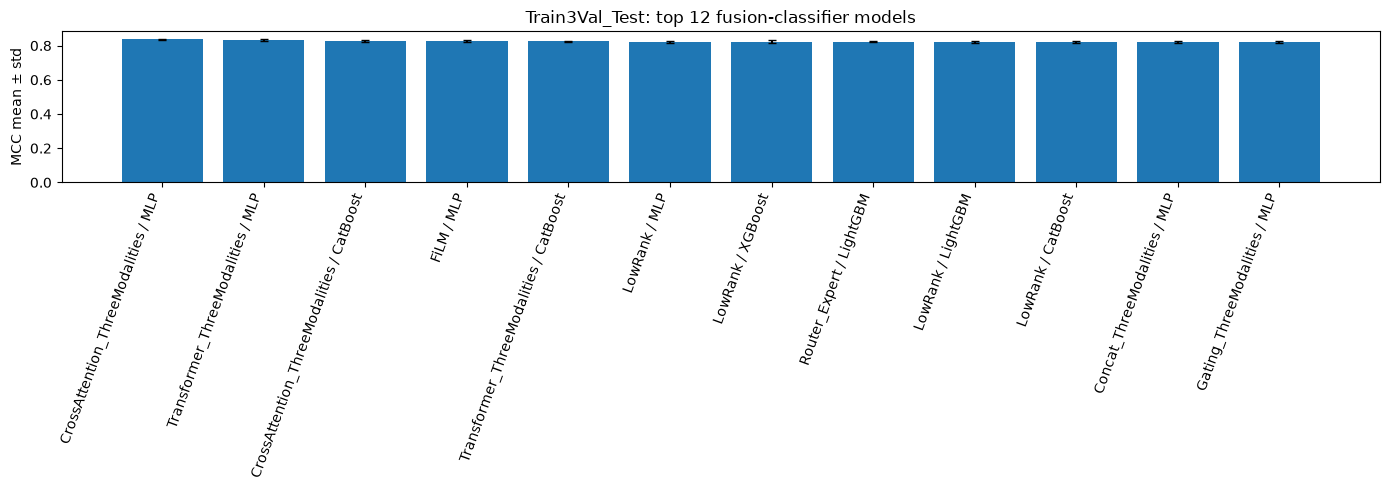

Test set: Train3Val_ClinVarHQ — test metrics mean/std across seeds


,Target_Config,Fusion,Classifier,Dataset,Accuracy_mean,Accuracy_std,Accuracy_count,Precision_mean,Precision_std,Precision_count,...,E2E_Total_Params_count,E2E_Param_Mem_MB_mean,E2E_Param_Mem_MB_std,E2E_Param_Mem_MB_count,Max_Peak_VRAM_MB_mean,Max_Peak_VRAM_MB_std,Max_Peak_VRAM_MB_count,Classifier_Tree_Leaves_mean,Classifier_Tree_Leaves_std,Classifier_Tree_Leaves_count
24,B_with_geometry,CrossAttention_ThreeModalities,MLP,Train3Val_ClinVarHQ,0.93882,0.005767,5,0.98062,0.008192,5,...,5,2297.61,0.0,5,2132.94,0.0,5,NaN,NaN,0
104,B_with_geometry,Transformer_ThreeModalities,MLP,Train3Val_ClinVarHQ,0.93516,0.003584,5,0.98040,0.005797,5,...,5,2218.90,0.0,5,2132.94,0.0,5,NaN,NaN,0
88,B_with_geometry,Router_Expert,MLP,Train3Val_ClinVarHQ,0.93060,0.013189,5,0.97438,0.011417,5,...,5,2194.58,0.0,5,2132.94,0.0,5,NaN,NaN,0
40,B_with_geometry,FiLM,MLP,Train3Val_ClinVarHQ,0.92632,0.007116,5,0.96664,0.004378,5,...,5,2190.15,0.0,5,2132.94,0.0,5,NaN,NaN,0
84,B_with_geometry,Router_Expert,LightGBM,Train3Val_ClinVarHQ,0.92432,0.002758,5,0.96652,0.004790,5,...,5,2194.58,0.0,5,2132.94,0.0,5,NaN,NaN,0
96,B_with_geometry,Transformer_ThreeModalities,CatBoost,Train3Val_ClinVarHQ,0.92320,0.007120,5,0.97360,0.002411,5,...,5,2218.90,0.0,5,2132.94,0.0,5,78643.2,20459.509750,5
8,B_with_geometry,Concat_ThreeModalities,MLP,Train3Val_ClinVarHQ,0.92346,0.011085,5,0.96570,0.012122,5,...,5,2183.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
12,B_with_geometry,Concat_ThreeModalities,XGBoost,Train3Val_ClinVarHQ,0.92320,0.008039,5,0.96124,0.006560,5,...,5,2183.77,0.0,5,2132.94,0.0,5,15700.4,1722.023606,5
52,B_with_geometry,Gating_ThreeModalities,LightGBM,Train3Val_ClinVarHQ,0.92290,0.004086,5,0.96408,0.005923,5,...,5,2192.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
80,B_with_geometry,Router_Expert,CatBoost,Train3Val_ClinVarHQ,0.92234,0.008446,5,0.96768,0.007259,5,...,5,2194.58,0.0,5,2132.94,0.0,5,119091.2,24217.654123,5


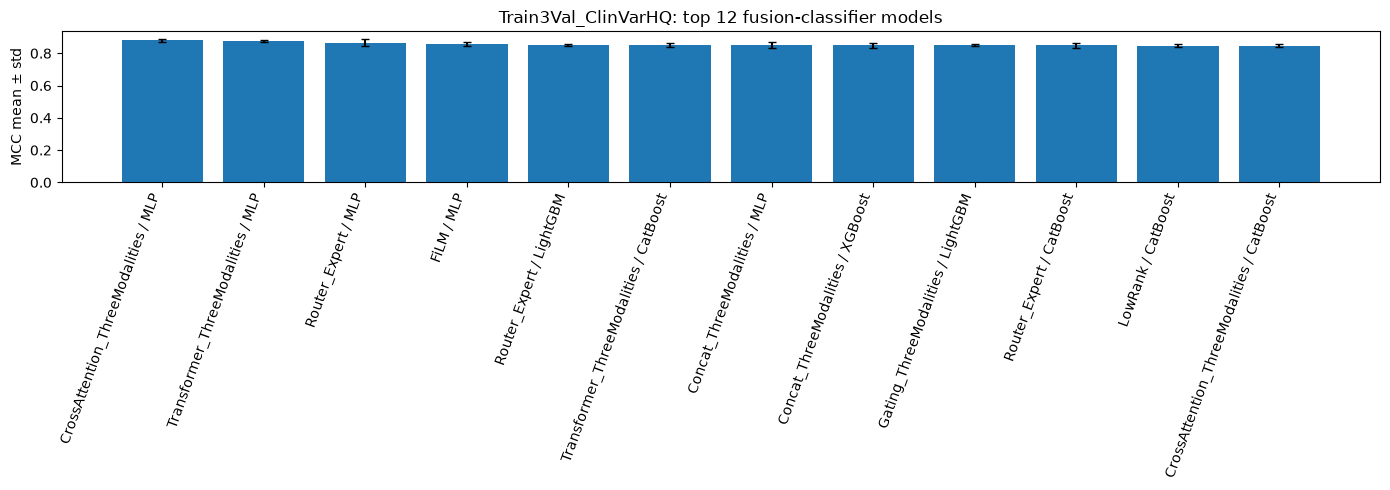

Test set: Train3Val_ProteinGym — test metrics mean/std across seeds


,Target_Config,Fusion,Classifier,Dataset,Accuracy_mean,Accuracy_std,Accuracy_count,Precision_mean,Precision_std,Precision_count,...,E2E_Total_Params_count,E2E_Param_Mem_MB_mean,E2E_Param_Mem_MB_std,E2E_Param_Mem_MB_count,Max_Peak_VRAM_MB_mean,Max_Peak_VRAM_MB_std,Max_Peak_VRAM_MB_count,Classifier_Tree_Leaves_mean,Classifier_Tree_Leaves_std,Classifier_Tree_Leaves_count
25,B_with_geometry,CrossAttention_ThreeModalities,MLP,Train3Val_ProteinGym,0.83628,0.007657,5,0.77736,0.014795,5,...,5,2297.61,0.0,5,2132.94,0.0,5,NaN,NaN,0
73,B_with_geometry,LowRank,MLP,Train3Val_ProteinGym,0.83396,0.014327,5,0.77572,0.021007,5,...,5,2205.10,0.0,5,2132.94,0.0,5,NaN,NaN,0
69,B_with_geometry,LowRank,LightGBM,Train3Val_ProteinGym,0.83398,0.007228,5,0.78028,0.015188,5,...,5,2205.10,0.0,5,2132.94,0.0,5,NaN,NaN,0
105,B_with_geometry,Transformer_ThreeModalities,MLP,Train3Val_ProteinGym,0.83152,0.011083,5,0.76828,0.014112,5,...,5,2218.90,0.0,5,2132.94,0.0,5,NaN,NaN,0
77,B_with_geometry,LowRank,XGBoost,Train3Val_ProteinGym,0.83180,0.007825,5,0.77482,0.010146,5,...,5,2205.10,0.0,5,2132.94,0.0,5,9521.2,2699.565095,5
9,B_with_geometry,Concat_ThreeModalities,MLP,Train3Val_ProteinGym,0.83002,0.005630,5,0.76738,0.013855,5,...,5,2183.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
85,B_with_geometry,Router_Expert,LightGBM,Train3Val_ProteinGym,0.83192,0.005112,5,0.77784,0.010687,5,...,5,2194.58,0.0,5,2132.94,0.0,5,NaN,NaN,0
89,B_with_geometry,Router_Expert,MLP,Train3Val_ProteinGym,0.82920,0.008103,5,0.76532,0.015669,5,...,5,2194.58,0.0,5,2132.94,0.0,5,NaN,NaN,0
49,B_with_geometry,Gating_ThreeModalities,CatBoost,Train3Val_ProteinGym,0.83232,0.002102,5,0.78102,0.005706,5,...,5,2192.77,0.0,5,2132.94,0.0,5,348569.6,206052.299256,5
57,B_with_geometry,Gating_ThreeModalities,MLP,Train3Val_ProteinGym,0.83004,0.004961,5,0.77078,0.010062,5,...,5,2192.77,0.0,5,2132.94,0.0,5,NaN,NaN,0


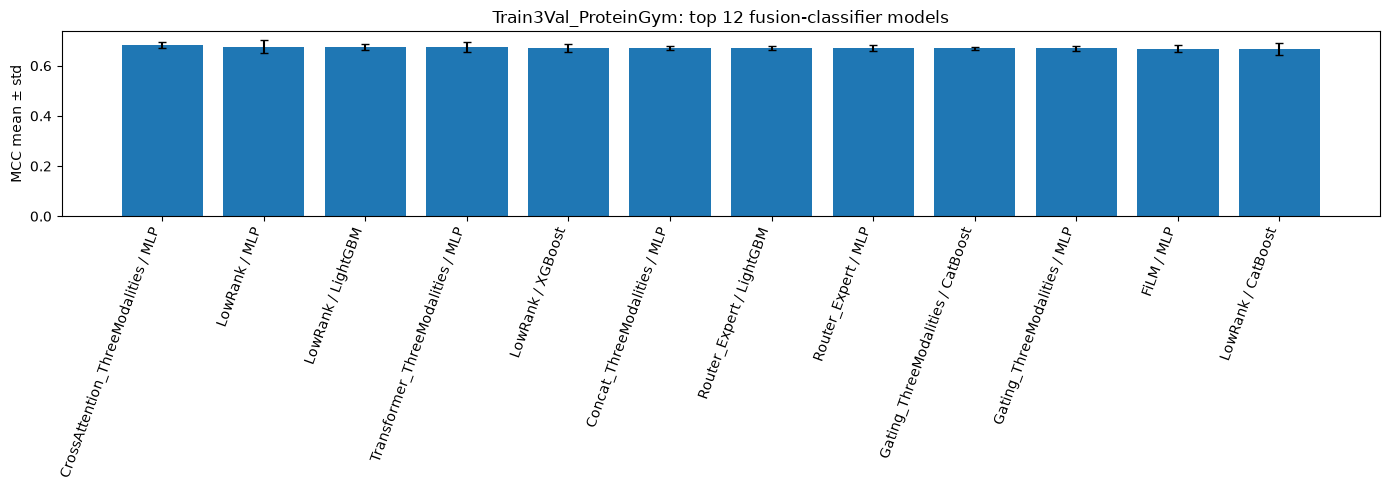

Test set: Train3Val_UniProt — test metrics mean/std across seeds


,Target_Config,Fusion,Classifier,Dataset,Accuracy_mean,Accuracy_std,Accuracy_count,Precision_mean,Precision_std,Precision_count,...,E2E_Total_Params_count,E2E_Param_Mem_MB_mean,E2E_Param_Mem_MB_std,E2E_Param_Mem_MB_count,Max_Peak_VRAM_MB_mean,Max_Peak_VRAM_MB_std,Max_Peak_VRAM_MB_count,Classifier_Tree_Leaves_mean,Classifier_Tree_Leaves_std,Classifier_Tree_Leaves_count
27,B_with_geometry,CrossAttention_ThreeModalities,MLP,Train3Val_UniProt,0.76728,0.008967,5,0.76136,0.008520,5,...,5,2297.61,0.0,5,2132.94,0.0,5,NaN,NaN,0
31,B_with_geometry,CrossAttention_ThreeModalities,XGBoost,Train3Val_UniProt,0.76216,0.002003,5,0.77136,0.007885,5,...,5,2297.61,0.0,5,2132.94,0.0,5,8135.6,750.292476,5
19,B_with_geometry,CrossAttention_ThreeModalities,CatBoost,Train3Val_UniProt,0.76202,0.002646,5,0.76750,0.004253,5,...,5,2297.61,0.0,5,2132.94,0.0,5,62361.6,8532.138583,5
3,B_with_geometry,Concat_ThreeModalities,CatBoost,Train3Val_UniProt,0.76126,0.002144,5,0.76156,0.007577,5,...,5,2183.77,0.0,5,2132.94,0.0,5,507494.4,219077.794139,5
95,B_with_geometry,Router_Expert,XGBoost,Train3Val_UniProt,0.76112,0.003911,5,0.76690,0.009929,5,...,5,2194.58,0.0,5,2132.94,0.0,5,11398.4,487.313862,5
83,B_with_geometry,Router_Expert,CatBoost,Train3Val_UniProt,0.76022,0.002827,5,0.75976,0.010166,5,...,5,2194.58,0.0,5,2132.94,0.0,5,119091.2,24217.654123,5
43,B_with_geometry,FiLM,MLP,Train3Val_UniProt,0.76022,0.003224,5,0.75836,0.010831,5,...,5,2190.15,0.0,5,2132.94,0.0,5,NaN,NaN,0
7,B_with_geometry,Concat_ThreeModalities,LightGBM,Train3Val_UniProt,0.75992,0.006380,5,0.76226,0.010697,5,...,5,2183.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
87,B_with_geometry,Router_Expert,LightGBM,Train3Val_UniProt,0.75978,0.003477,5,0.75888,0.005102,5,...,5,2194.58,0.0,5,2132.94,0.0,5,NaN,NaN,0
71,B_with_geometry,LowRank,LightGBM,Train3Val_UniProt,0.75948,0.010006,5,0.76680,0.015822,5,...,5,2205.10,0.0,5,2132.94,0.0,5,NaN,NaN,0


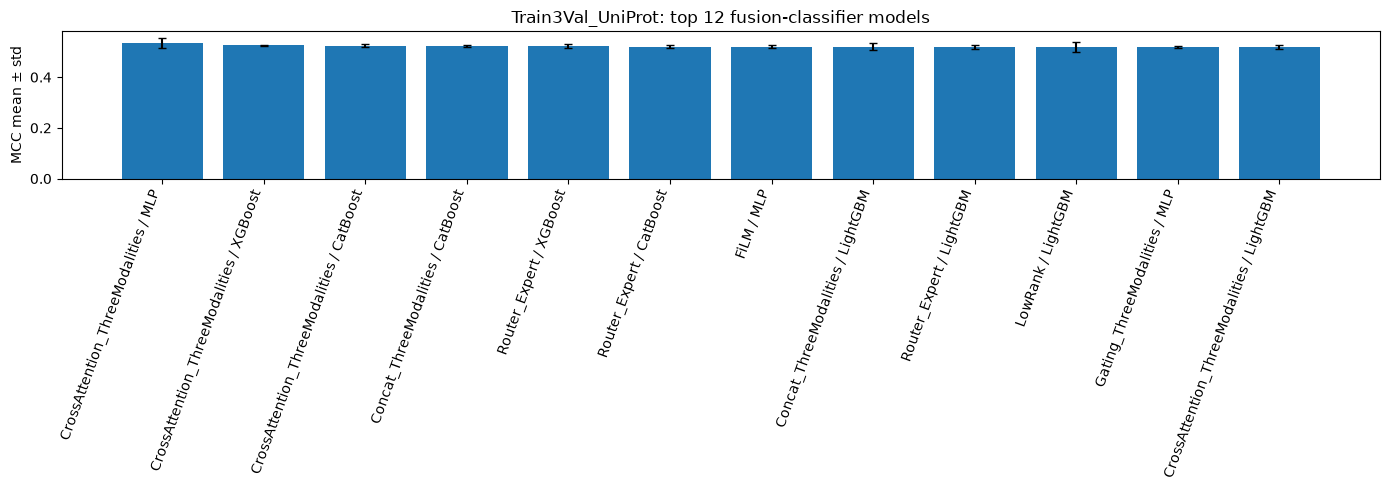

Profiling summary across seeds:


,Target_Config,Fusion,Classifier,FM_GFLOPs/Sample_mean,FM_GFLOPs/Sample_std,FM_GFLOPs/Sample_count,FM_Latency_ms/Sample_mean,FM_Latency_ms/Sample_std,FM_Latency_ms/Sample_count,Geom_GFLOPs/Sample_mean,...,E2E_Total_Params_count,E2E_Param_Mem_MB_mean,E2E_Param_Mem_MB_std,E2E_Param_Mem_MB_count,Max_Peak_VRAM_MB_mean,Max_Peak_VRAM_MB_std,Max_Peak_VRAM_MB_count,Classifier_Tree_Leaves_mean,Classifier_Tree_Leaves_std,Classifier_Tree_Leaves_count
3,B_with_geometry,Concat_ThreeModalities,XGBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2183.77,0.0,5,2132.94,0.0,5,15700.4,1722.023606,5
11,B_with_geometry,FiLM,XGBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2190.15,0.0,5,2132.94,0.0,5,8596.0,2245.148659,5
8,B_with_geometry,FiLM,CatBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2190.15,0.0,5,2132.94,0.0,5,72601.6,27719.965599,5
19,B_with_geometry,LowRank,XGBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2205.10,0.0,5,2132.94,0.0,5,9521.2,2699.565095,5
15,B_with_geometry,Gating_ThreeModalities,XGBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2192.77,0.0,5,2132.94,0.0,5,14312.0,1604.619581,5
9,B_with_geometry,FiLM,LightGBM,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2190.15,0.0,5,2132.94,0.0,5,NaN,NaN,0
23,B_with_geometry,Router_Expert,XGBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2194.58,0.0,5,2132.94,0.0,5,11398.4,487.313862,5
17,B_with_geometry,LowRank,LightGBM,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2205.10,0.0,5,2132.94,0.0,5,NaN,NaN,0
1,B_with_geometry,Concat_ThreeModalities,LightGBM,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2183.77,0.0,5,2132.94,0.0,5,NaN,NaN,0
0,B_with_geometry,Concat_ThreeModalities,CatBoost,819.5242,0.0,5,33.6,0.0,5,0.0,...,5,2183.77,0.0,5,2132.94,0.0,5,507494.4,219077.794139,5


Seed-level profiling records:


,Target_Config,Fusion,Classifier,Seed,FM_GFLOPs/Sample,FM_Latency_ms/Sample,Geom_GFLOPs/Sample,Geom_Latency_ms/Sample,Classifier_GFLOPs/Sample,Classifier_Latency_ms/Sample,...,Classifier_Model_Mem_MB,Classifier_Peak_VRAM_MB,E2E_GFLOPs/Sample,E2E_Latency_ms/Sample,E2E_Total_Params,E2E_Param_Mem_MB,Max_Peak_VRAM_MB,Classifier_Tree_Leaves,Classifier_GFLOPs_Note,Classifier_Model_Mem_Scope
0,B_with_geometry,Concat_ThreeModalities,MLP,5,819.5242,33.6,0.0,0.89,0.0069,0.0100,...,13.0942,58.5500,819.5311,34.5000,1141489313,2183.77,2132.94,NaN,NaN,NaN
1,B_with_geometry,Concat_ThreeModalities,XGBoost,5,819.5242,33.6,0.0,0.00,NaN,0.0329,...,14.9129,24.6030,NaN,33.6329,1141489313,2183.77,2132.94,14665.0,Tree operations are not represented as neural-...,fusion encoder checkpoint + serialized tree model
2,B_with_geometry,Concat_ThreeModalities,CatBoost,5,819.5242,33.6,0.0,0.00,NaN,0.0550,...,22.8134,24.6030,NaN,33.6550,1141489313,2183.77,2132.94,620544.0,Tree operations are not represented as neural-...,fusion encoder checkpoint + serialized tree model
3,B_with_geometry,Concat_ThreeModalities,LightGBM,5,819.5242,33.6,0.0,0.00,NaN,0.0506,...,16.5817,24.6030,NaN,33.6506,1141489313,2183.77,2132.94,NaN,Tree operations are not represented as neural-...,fusion encoder checkpoint + serialized tree model
4,B_with_geometry,Concat_ThreeModalities,MLP,6,819.5242,33.6,0.0,0.89,0.0069,0.0100,...,13.0942,71.6400,819.5311,34.5000,1141489313,2183.77,2132.94,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
135,B_with_geometry,Router_Expert,LightGBM,37,819.5242,33.6,0.0,0.00,NaN,0.0633,...,26.5158,43.9336,NaN,33.6633,1144322984,2194.58,2132.94,NaN,Tree operations are not represented as neural-...,fusion encoder checkpoint + serialized tree model
136,B_with_geometry,Router_Expert,MLP,42,819.5242,33.6,0.0,0.89,0.0125,0.0200,...,23.9196,116.1400,819.5367,34.5100,1144322984,2194.58,2132.94,NaN,NaN,NaN
137,B_with_geometry,Router_Expert,XGBoost,42,819.5242,33.6,0.0,0.00,NaN,0.0453,...,25.3256,43.9336,NaN,33.6453,1144322984,2194.58,2132.94,11234.0,Tree operations are not represented as neural-...,fusion encoder checkpoint + serialized tree model
138,B_with_geometry,Router_Expert,CatBoost,42,819.5242,33.6,0.0,0.00,NaN,0.0701,...,25.1583,43.9336,NaN,33.6701,1144322984,2194.58,2132.94,76288.0,Tree operations are not represented as neural-...,fusion encoder checkpoint + serialized tree model


Detailed test metrics: D:\Missense_variant_pathogenicity_prediction\experiments\fusion_classifier_benchmark_20261120_192605\module06_architecture_experiments\fusion_classifier_benchmark\seed_level_test_metrics.csv
Detailed predictions: D:\Missense_variant_pathogenicity_prediction\experiments\fusion_classifier_benchmark_20261120_192605\module06_architecture_experiments\fusion_classifier_benchmark\seed_level_test_predictions.csv


In [4]:
import matplotlib.pyplot as plt
from core.module06_architecture_experiments.fusion_classifier_benchmark import summarize_saved_fusion_classifier_benchmark
SUMMARY_ROOT = BATCH_RUN_DIR / 'module06_architecture_experiments' / 'fusion_classifier_benchmark' / 'summaries'
SAVED_SUMMARY = summarize_saved_fusion_classifier_benchmark(
    BATCH_RUN_DIR / 'module06_architecture_experiments' / 'fusion_classifier_benchmark', seeds=SEEDS
)
TEST_MEAN_STD = pd.read_csv(SUMMARY_ROOT / 'test_mean_std_by_fusion_classifier_dataset.csv')
VALIDATION_MEAN_STD = pd.read_csv(SUMMARY_ROOT / 'validation_mean_std_by_fusion_classifier.csv')
PROFILE_BY_SEED = pd.read_csv(SUMMARY_ROOT / 'profiling_by_seed.csv')
PROFILE_MEAN_STD = pd.read_csv(SUMMARY_ROOT / 'profiling_mean_std_by_fusion_classifier.csv')
COMPLETION_INVENTORY = pd.read_csv(SUMMARY_ROOT / 'completion_inventory.csv')
print('Validation mean/std across five seeds:')
display(VALIDATION_MEAN_STD.sort_values('Val_MCC_mean', ascending=False))
print('Completion status:')
display(COMPLETION_INVENTORY)

for dataset_name in [dataset['name'] for dataset in DATASETS]:
    table = TEST_MEAN_STD[TEST_MEAN_STD['Dataset'].astype(str).eq(dataset_name)].copy()
    if table.empty:
        print(f'No completed results for {dataset_name}')
        continue
    table = table.sort_values('MCC_mean', ascending=False)
    print(f'Test set: {dataset_name} — test metrics mean/std across seeds')
    display(table)
    top = table.head(12).copy()
    top['Model'] = top['Fusion'].astype(str) + ' / ' + top['Classifier'].astype(str)
    plt.figure(figsize=(14, 5))
    plt.bar(top['Model'], top['MCC_mean'], yerr=top['MCC_std'].fillna(0), capsize=3)
    plt.xticks(rotation=70, ha='right')
    plt.ylabel('MCC mean ± std')
    plt.title(f'{dataset_name}: top 12 fusion-classifier models')
    plt.tight_layout()
    plt.show()

print('Profiling summary across seeds:')
display(PROFILE_MEAN_STD.sort_values('E2E_Latency_ms/Sample_mean', ascending=True))
print('Seed-level profiling records:')
display(PROFILE_BY_SEED)
print('Detailed test metrics:', BATCH_RUN_DIR / 'module06_architecture_experiments' / 'fusion_classifier_benchmark' / 'seed_level_test_metrics.csv')
print('Detailed predictions:', BATCH_RUN_DIR / 'module06_architecture_experiments' / 'fusion_classifier_benchmark' / 'seed_level_test_predictions.csv')
